## 0. Описание задачи

Название работы: предсказание оценок в отзывах на товары Amazon

Автор: Титаев Максим Алексеевич

Данные: Consumer Reviews of Amazon Products, файл 1429_1.csv

Один объект: один отзыв покупателя

Цель: по тексту отзыва и выбранным характеристикам определить оценку покупателя

Тип задачи: классификация на пять классов — оценки 1, 2, 3, 4, 5

Целевая переменная: столбец reviews.rating

Источник: ссылка на датасет https://www.kaggle.com/datasets/datafiniti/consumer-reviews-of-amazon-products

## 1. Загрузка и первичный просмотр данных

In [26]:
import pandas as pd

data = pd.read_csv("/content/1429_1.csv", low_memory=False)

data.head()

,id,name,asins,brand,categories,keys,manufacturer,reviews.date,reviews.dateAdded,reviews.dateSeen,...,reviews.doRecommend,reviews.id,reviews.numHelpful,reviews.rating,reviews.sourceURLs,reviews.text,reviews.title,reviews.userCity,reviews.userProvince,reviews.username
0,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-13T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,5.0,http://reviews.bestbuy.com/3545/5620406/review...,This product so far has not disappointed. My c...,Kindle,NaN,NaN,Adapter
1,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-13T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,5.0,http://reviews.bestbuy.com/3545/5620406/review...,great for beginner or experienced person. Boug...,very fast,NaN,NaN,truman
2,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-13T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,5.0,http://reviews.bestbuy.com/3545/5620406/review...,Inexpensive tablet for him to use and learn on...,Beginner tablet for our 9 year old son.,NaN,NaN,DaveZ
3,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-13T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,4.0,http://reviews.bestbuy.com/3545/5620406/review...,I've had my Fire HD 8 two weeks now and I love...,Good!!!,NaN,NaN,Shacks
4,AVqkIhwDv8e3D1O-lebb,"All-New Fire HD 8 Tablet, 8 HD Display, Wi-Fi,...",B01AHB9CN2,Amazon,"Electronics,iPad & Tablets,All Tablets,Fire Ta...","841667104676,amazon/53004484,amazon/b01ahb9cn2...",Amazon,2017-01-12T00:00:00.000Z,2017-07-03T23:33:15Z,"2017-06-07T09:04:00.000Z,2017-04-30T00:45:00.000Z",...,True,NaN,0.0,5.0,http://reviews.bestbuy.com/3545/5620406/review...,I bought this for my grand daughter when she c...,Fantastic Tablet for kids,NaN,NaN,explore42


In [4]:
print("Размер таблицы:", data.shape)

data.info()

Размер таблицы: (34660, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34660 entries, 0 to 34659
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    34660 non-null  object 
 1   name                  27900 non-null  object 
 2   asins                 34658 non-null  object 
 3   brand                 34660 non-null  object 
 4   categories            34660 non-null  object 
 5   keys                  34660 non-null  object 
 6   manufacturer          34660 non-null  object 
 7   reviews.date          34621 non-null  object 
 8   reviews.dateAdded     24039 non-null  object 
 9   reviews.dateSeen      34660 non-null  object 
 10  reviews.didPurchase   1 non-null      object 
 11  reviews.doRecommend   34066 non-null  object 
 12  reviews.id            1 non-null      float64
 13  reviews.numHelpful    34131 non-null  float64
 14  reviews.rating        34627 non-null  floa

In [5]:
missing = data.isna().sum()

print(missing.sort_values(ascending=False))

reviews.userCity        34660
reviews.userProvince    34660
reviews.id              34659
reviews.didPurchase     34659
reviews.dateAdded       10621
name                     6760
reviews.doRecommend       594
reviews.numHelpful        529
reviews.date               39
reviews.rating             33
reviews.username            7
reviews.title               6
asins                       2
reviews.text                1
categories                  0
id                          0
brand                       0
reviews.dateSeen            0
keys                        0
manufacturer                0
reviews.sourceURLs          0
dtype: int64


## 2. Подготовка целевой переменной и разделение данных

In [6]:
labeled_data = data.dropna(subset=["reviews.rating"]).copy()

print("До удаления:", len(data))
print("После удаления:", len(labeled_data))

До удаления: 34660
После удаления: 34627


In [7]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    labeled_data,
    test_size=0.2,
    random_state=42,
    stratify=labeled_data["reviews.rating"]
)

print("Обучающая выборка:", len(train_data))
print("Тестовая выборка:", len(test_data))

Обучающая выборка: 27701
Тестовая выборка: 6926


## 3. Исследование и визуализация данных

reviews.rating
1.0      328
2.0      322
3.0     1199
4.0     6833
5.0    19019
Name: count, dtype: int64


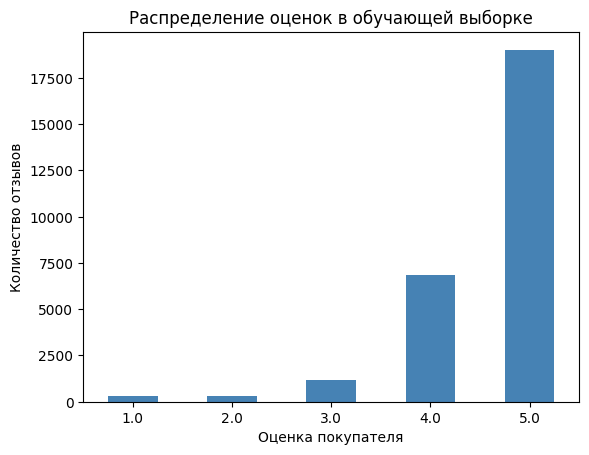

In [8]:
import matplotlib.pyplot as plt

rating_counts = train_data["reviews.rating"].value_counts().sort_index()

print(rating_counts)

rating_counts.plot(kind="bar", color="steelblue")

plt.title("Распределение оценок в обучающей выборке")
plt.xlabel("Оценка покупателя")
plt.ylabel("Количество отзывов")
plt.xticks(rotation=0)
plt.show()

На данной диаграмме видно, что оценка "5" преобладает её доля составляет около 68,7%. Самые редковстречающиеся оценки это - 1 и 2, доля каждой из них составляет примерно 1,2%. И из этого видно, что классы сильно несбалансированы. Модель, которая всегда предсказывает оценку «5», получит около 68,7% правильных ответов, поэтому при оценке качества необходимо учитывать результаты отдельно для каждого класса.

In [9]:
review_length = train_data["reviews.text"].str.len()

statistics = pd.DataFrame({
    "Голоса за полезность": train_data["reviews.numHelpful"],
    "Длина отзыва в символах": review_length
})

statistics.describe()

,Голоса за полезность,Длина отзыва в символах
count,27313.000000,27701.000000
mean,0.618350,158.668857
std,13.112531,186.244384
min,0.000000,3.000000
25%,0.000000,70.000000
50%,0.000000,106.000000
75%,0.000000,184.000000
max,814.000000,10670.000000


По таблице видно, что средняя длина отзыва составляет около 160 символов, а медиана — 106 символов. У половины отзывов длина находится в пределах от 70 до 184 символов. Самый длинный отзыв содержит 10670 символов. Большинство отзывов не имеют голосов за полезность: даже значение третьего квартиля равно нулю. При этом максимальное количество голосов — 814, поэтому дальше проверим такие необычные значения.

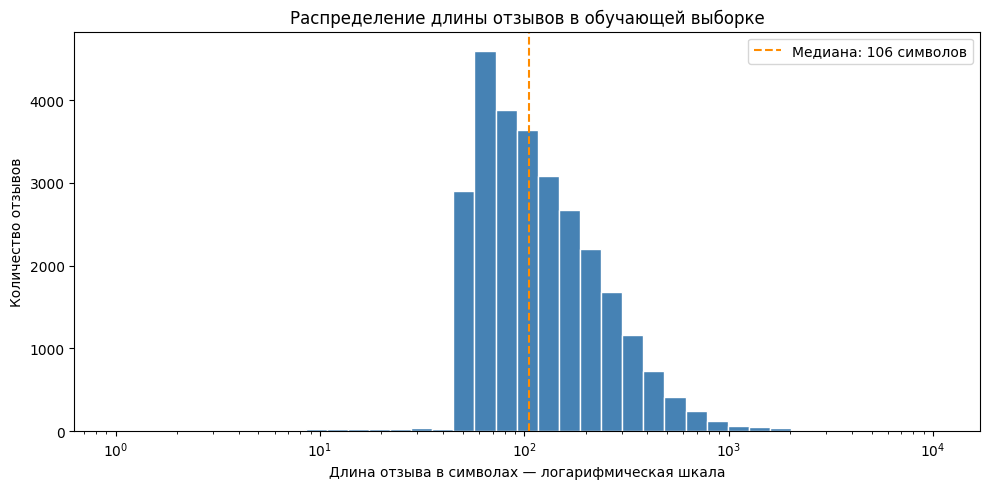

In [27]:
import numpy as np

lengths = review_length.dropna()
positive_lengths = lengths[lengths > 0]

bins = np.geomspace(1, max(2, positive_lengths.max()), 40)

plt.figure(figsize=(10, 5))
plt.hist(
    positive_lengths,
    bins=bins,
    color="steelblue",
    edgecolor="white"
)

plt.xscale("log")
plt.axvline(
    lengths.median(),
    color="darkorange",
    linestyle="--",
    label=f"Медиана: {lengths.median():.0f} символов"
)

plt.title("Распределение длины отзывов в обучающей выборке")
plt.xlabel("Длина отзыва в символах — логарифмическая шкала")
plt.ylabel("Количество отзывов")
plt.legend()
plt.tight_layout()
plt.show()

На графике видно, что короткие отзывы встречаются чаще длинных. Медианная длина составляет 106 символов: примерно половина отзывов не длиннее этого значения. Также есть отдельные отзывы длиной в несколько тысяч символов. По горизонтальной оси используется логарифмическая шкала, чтобы показать весь диапазон длин на одном графике.

In [10]:
correlation_data = statistics.copy()
correlation_data["Оценка"] = train_data["reviews.rating"]

correlation_data.corr()

,Голоса за полезность,Длина отзыва в символах,Оценка
Голоса за полезность,1.000000,0.228989,-0.044055
Длина отзыва в символах,0.228989,1.000000,-0.103835
Оценка,-0.044055,-0.103835,1.000000


Сильных линейных связей не обнаружено, наиболее заметная связь — между длиной отзыва и голосами за полезность. Корреляция между длиной отзыва и голосами за полезность составляет около 0,229, что указывает на слабую положительную линейную связь

## 4. Исследование выбросов

In [11]:
statistics.sort_values(
    "Голоса за полезность",
    ascending=False
).head(10)

,Голоса за полезность,Длина отзыва в символах
28947,814.0,1694
21219,780.0,1651
34627,744.0,1688
2882,730.0,1773
34625,660.0,1803
21218,650.0,1684
28668,629.0,1713
28670,422.0,185
29543,302.0,1709
21562,292.0,609


In [12]:
q1 = statistics.quantile(0.25)
q3 = statistics.quantile(0.75)

iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = statistics.lt(lower) | statistics.gt(upper)

outlier_summary = pd.DataFrame({
    "Нижняя граница": lower,
    "Верхняя граница": upper,
    "Число срабатываний": outliers.sum(),
    "Доля среди заполненных, %":
        100 * outliers.sum() / statistics.count()
})

outlier_summary

,Нижняя граница,Верхняя граница,Число срабатываний,"Доля среди заполненных, %"
Голоса за полезность,0.0,0.0,2659,9.735291
Длина отзыва в символах,-101.0,355.0,1999,7.216346


Метод выделил необычные значения. Однако большинство отзывов не имеют голосов за полезность, поэтому любой отзыв хотя бы с одним голосом попал в выбросы.

In [13]:
longest_indices = statistics[
    "Длина отзыва в символах"
].nlargest(3).index

for index in longest_indices:
    print("Индекс:", index)
    print("Длина:", review_length.loc[index])
    print(train_data.loc[index, "reviews.text"])
    print()

Индекс: 21231
Длина: 10670
This is a review of the Kindle Paperwhite launched July 2015. Essentially. the same as the previous Kindle Paperwhite but with a fantastic upgraded (300 dpi) screen, more memory and storage it's a terrific reading device. This review aims to describe both this product, and compare it with the other Kindle devices available to help you choose the best one for you.Before I start, Ive noticed several complains about Kindle not supporting the ePub format used by Canadian public libraries. Dont be put off, theres a solution in the Frequently Asked Questions section below.This review is broken up into sections so you can skip the less interesting bits. If youre in a hurry Ive included a summary at the start, and a Frequently Asked Questions section at the end.Summary - What can you do with it-----------------------------------------* Read a book. It can store 1,000s of books - take an entire library away with you on holiday.* Buy a book. You can browse the Amazon k

Метод выделил отзывы длиннее 355 символов как возможные выбросы. Однако большая длина сама по себе не означает ошибку: покупатель может подробно описывать товар и свой опыт использования. Поэтому отзывы не удаляем только из-за их длины. Записи с большим количеством голосов за полезность также сохраняем, поскольку такие значения возможны у популярных отзывов.

## 5. Обработка пропущенных значений и выбор признаков

In [14]:
missing_summary = pd.DataFrame({
    "Количество пропусков": train_data.isna().sum(),
    "Доля пропусков, %": train_data.isna().mean() * 100
})

missing_summary.sort_values(
    "Доля пропусков, %",
    ascending=False
)

,Количество пропусков,"Доля пропусков, %"
reviews.userCity,27701,100.000000
reviews.userProvince,27701,100.000000
reviews.id,27700,99.996390
reviews.didPurchase,27700,99.996390
reviews.dateAdded,8446,30.489874
name,5384,19.436121
reviews.doRecommend,441,1.592000
reviews.numHelpful,388,1.400671
reviews.date,22,0.079420
reviews.username,6,0.021660


In [15]:
empty_columns = [
    "reviews.userCity",
    "reviews.userProvince",
    "reviews.id",
    "reviews.didPurchase"
]

train_clean = train_data.drop(columns=empty_columns).copy()
test_clean = test_data.drop(columns=empty_columns).copy()

print("Обучающая выборка:", train_clean.shape)
print("Тестовая выборка:", test_clean.shape)

Обучающая выборка: (27701, 17)
Тестовая выборка: (6926, 17)


Столбцы reviews.userCity и reviews.userProvince полностью пустые, а в reviews.id и reviews.didPurchase заполнено только по одному значению в обучающей выборке. Поэтому эти четыре столбца исключаем. Количество отзывов при этом не меняется.

In [16]:
feature_columns = [
    "reviews.text",
    "reviews.title",
    "name",
    "brand",
    "categories",
    "manufacturer"
]

X_train = train_clean[feature_columns].copy()
X_test = test_clean[feature_columns].copy()

fill_values = {
    "reviews.text": "",
    "reviews.title": "",
    "name": "Unknown",
    "brand": "Unknown",
    "categories": "Unknown",
    "manufacturer": "Unknown"
}

X_train = X_train.fillna(fill_values)
X_test = X_test.fillna(fill_values)

y_train = train_clean["reviews.rating"].astype(int)
y_test = test_clean["reviews.rating"].astype(int)

print("Пропусков в обучающих признаках:", X_train.isna().sum().sum())
print("Пропусков в тестовых признаках:", X_test.isna().sum().sum())

Пропусков в обучающих признаках: 0
Пропусков в тестовых признаках: 0


Для предсказания используем текст и заголовок отзыва, название товара, бренд, категории и производителя. Идентификаторы и ссылки исключаем, поскольку они служат для обозначения записей и источников. Признак рекомендации покупателя также исключаем, чтобы модель не опиралась на подсказку, тесно связанную с оценкой. Голоса за полезность не используем, поскольку у нового отзыва они ещё не накоплены. Пропуски в тексте и заголовке заменяем пустыми строками, а в характеристиках товара — значением Unknown. После заполнения в выбранных признаках пропусков не осталось.

## 6. Преобразование категориальных и текстовых признаков

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

categorical_columns = [
    "name",
    "brand",
    "categories",
    "manufacturer"
]

preprocessor = ColumnTransformer([
    (
        "review_text",
        TfidfVectorizer(max_features=5000, min_df=2),
        "reviews.text"
    ),
    (
        "review_title",
        TfidfVectorizer(max_features=1000, min_df=2),
        "reviews.title"
    ),
    (
        "product_categories",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_columns
    )
])

print("Способы преобразования признаков настроены")

Способы преобразования признаков настроены


Модель работает с числами, поэтому текст и категории нужно преобразовать. Для текста и заголовка отзыва используем TF-IDF: он представляет каждый отзыв набором числовых весов слов. Для характеристик товара используем One-hot encoding: каждой категории соответствует отдельный столбец со значениями 0 или 1. Словарь слов и набор категорий определяются только по обучающим данным, чтобы информация из тестовой выборки не влияла на обучение.

## 7. Нормализация признаков и обучение KNN

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Normalizer
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("normalizer", Normalizer()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute"
    ))
])

knn_model.fit(X_train, y_train)

print("Модель ближайших соседей обучена")

Модель ближайших соседей обучена


После объединения признаков используем Normalizer: он приводит вектор каждого отзыва к единичной длине. Для первого метода выбрали классификатор ближайших соседей — он определяет оценку по оценкам похожих отзывов. Сходство измеряем косинусным расстоянием, которое подходит для представления текста через TF-IDF. При этом расстоянии общая нормализация вектора не меняет выбор соседей. Для первого запуска берём 5 соседей, затем проверим несколько вариантов с помощью кросс-валидации.

## 8. Подбор числа соседей

In [20]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

knn_search = GridSearchCV(
    estimator=knn_model,
    param_grid={
        "classifier__n_neighbors": [3, 5, 11]
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    verbose=1
)

knn_search.fit(X_train, y_train)

print("Лучшее число соседей:", knn_search.best_params_)
print("Средний F1-macro:", knn_search.best_score_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Лучшее число соседей: {'classifier__n_neighbors': 5}
Средний F1-macro: 0.3228783900934048


Для выбора числа соседей проверили значения 3, 5 и 11 с помощью кросс-валидации на трёх частях обучающей выборки. Для сравнения использовали F1-macro, чтобы каждый класс имел одинаковый вес независимо от количества отзывов. Среди проверенных вариантов лучший результат получен при 5 соседях: средний F1-macro составил около 0,323. Тестовая выборка при подборе параметра не использовалась.

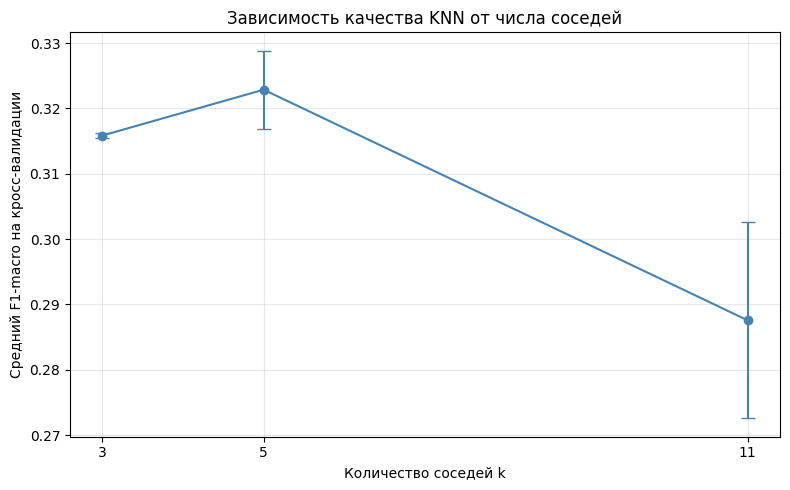

In [28]:
cv_results = pd.DataFrame(knn_search.cv_results_)
cv_results["k"] = cv_results["param_classifier__n_neighbors"].astype(int)
cv_results = cv_results.sort_values("k")

plt.figure(figsize=(8, 5))

plt.errorbar(
    cv_results["k"],
    cv_results["mean_test_score"],
    yerr=cv_results["std_test_score"],
    fmt="o-",
    capsize=5,
    color="steelblue"
)

plt.xticks(cv_results["k"])
plt.xlabel("Количество соседей k")
plt.ylabel("Средний F1-macro на кросс-валидации")
plt.title("Зависимость качества KNN от числа соседей")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

На графике видно, что при 5 соседях средний F1-macro составляет около 0,323 — это лучший результат среди проверенных вариантов. При 3 соседях он немного ниже, около 0,316, а при 11 снижается примерно до 0,288. Вертикальные отрезки показывают разброс результатов между частями кросс-валидации. При 11 соседях этот разброс больше, то есть качество сильнее зависит от разбиения данных.

In [21]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

best_knn = knn_search.best_estimator_

knn_train_pred = best_knn.predict(X_train)
knn_test_pred = best_knn.predict(X_test)

for name, actual, predicted in [
    ("Обучающая", y_train, knn_train_pred),
    ("Тестовая", y_test, knn_test_pred)
]:
    accuracy = accuracy_score(actual, predicted)

    print(name, "выборка")
    print(f"Доля правильных ответов: {accuracy:.3f}")
    print(f"Доля ошибок: {1 - accuracy:.3f}")
    print(f"F1-macro: {f1_score(actual, predicted, average='macro'):.3f}")
    print()

print("Результаты по классам на тестовой выборке:")
print(classification_report(y_test, knn_test_pred, zero_division=0))

Обучающая выборка
Доля правильных ответов: 0.768
Доля ошибок: 0.232
F1-macro: 0.529

Тестовая выборка
Доля правильных ответов: 0.677
Доля ошибок: 0.323
F1-macro: 0.353

Результаты по классам на тестовой выборке:
              precision    recall  f1-score   support

           1       0.46      0.20      0.27        82
           2       0.26      0.11      0.16        80
           3       0.35      0.16      0.22       300
           4       0.40      0.25      0.31      1708
           5       0.74      0.88      0.80      4756

    accuracy                           0.68      6926
   macro avg       0.44      0.32      0.35      6926
weighted avg       0.63      0.68      0.64      6926



## 9. Оценка качества KNN

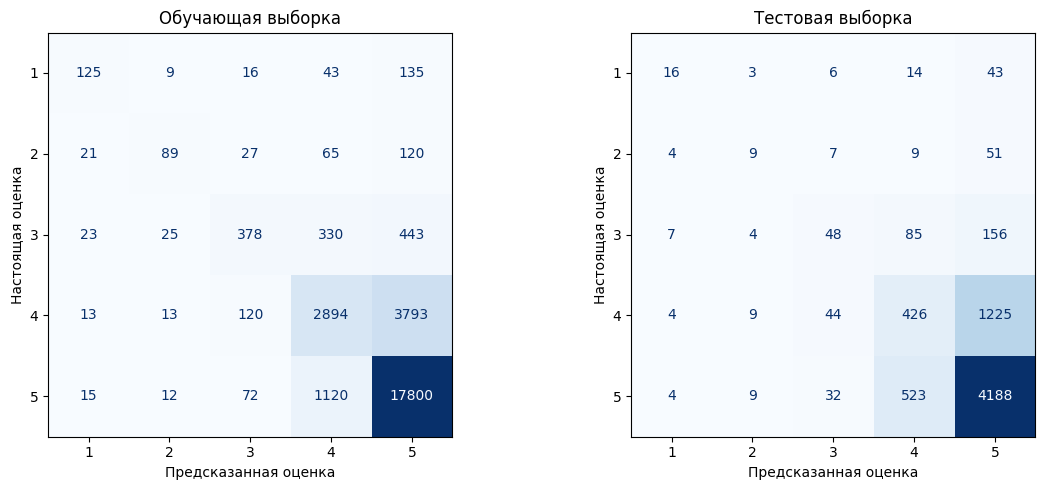

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, actual, predicted, title in [
    (axes[0], y_train, knn_train_pred, "Обучающая выборка"),
    (axes[1], y_test, knn_test_pred, "Тестовая выборка")
]:
    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=[1, 2, 3, 4, 5],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Предсказанная оценка")
    ax.set_ylabel("Настоящая оценка")

plt.tight_layout()
plt.show()

На обучающей выборке точность метода ближайших соседей составила 76,8%, а на тестовой — 67,7%. Снижение качества на новых данных указывает на некоторое переобучение. По матрице ошибок видно, что модель часто предсказывает пятёрку: например, 1225 настоящих четвёрок она приняла за пятёрки. Единицы и двойки распознаются плохо. Если всегда предсказывать пятёрку, точность на тестовой выборке составит около 68,7%, поэтому по общей точности KNN немного уступает этому простому варианту.

## 10. Обучение логистической регрессии

In [23]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("normalizer", Normalizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

logistic_train_pred = logistic_model.predict(X_train)
logistic_test_pred = logistic_model.predict(X_test)

for name, actual, predicted in [
    ("Обучающая", y_train, logistic_train_pred),
    ("Тестовая", y_test, logistic_test_pred)
]:
    accuracy = accuracy_score(actual, predicted)

    print(name, "выборка")
    print(f"Доля правильных ответов: {accuracy:.3f}")
    print(f"Доля ошибок: {1 - accuracy:.3f}")
    print(f"F1-macro: {f1_score(actual, predicted, average='macro'):.3f}")
    print()

Обучающая выборка
Доля правильных ответов: 0.757
Доля ошибок: 0.243
F1-macro: 0.362

Тестовая выборка
Доля правильных ответов: 0.734
Доля ошибок: 0.266
F1-macro: 0.324



Для сравнения выбрали логистическую регрессию. Несмотря на название, она решает задачу классификации: учится связывать слова и характеристики товара с оценками покупателей. Этот метод подходит для большого количества разреженных признаков, полученных с помощью TF-IDF и One-hot encoding. Используем те же признаки и то же разделение на обучение и тест, чтобы сравнить результаты двух методов.

## 11. Оценка качества логистической регрессии

              precision    recall  f1-score   support

           1       0.67      0.07      0.13        82
           2       1.00      0.01      0.02        80
           3       0.49      0.15      0.23       300
           4       0.54      0.30      0.39      1708
           5       0.77      0.95      0.85      4756

    accuracy                           0.73      6926
   macro avg       0.69      0.30      0.32      6926
weighted avg       0.70      0.73      0.69      6926



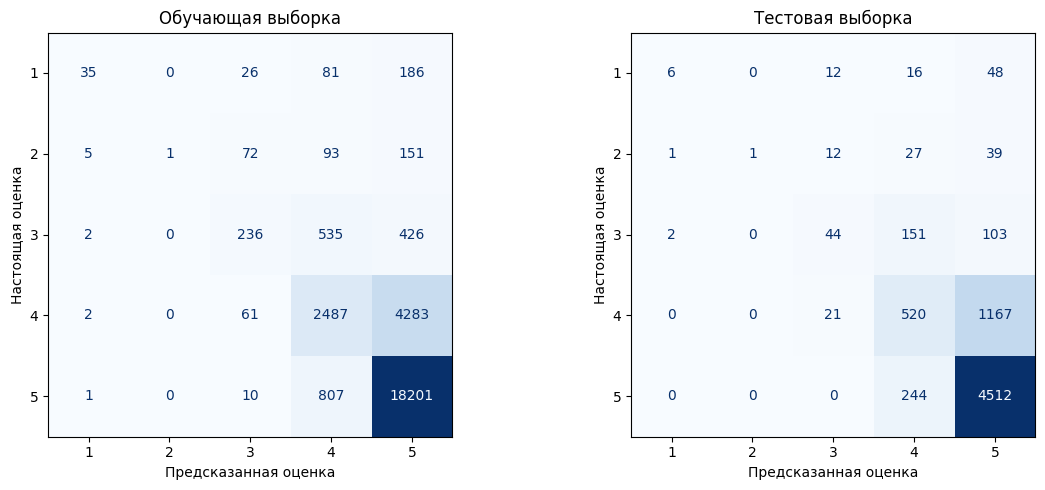

In [24]:
print(classification_report(
    y_test,
    logistic_test_pred,
    zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, actual, predicted, title in [
    (axes[0], y_train, logistic_train_pred, "Обучающая выборка"),
    (axes[1], y_test, logistic_test_pred, "Тестовая выборка")
]:
    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted,
        labels=[1, 2, 3, 4, 5],
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Предсказанная оценка")
    ax.set_ylabel("Настоящая оценка")

plt.tight_layout()
plt.show()

На обучающей выборке точность логистической регрессии составила 75,7%, на тестовой — 73,4%. Разница меньше, чем у метода ближайших соседей. Однако по матрице ошибок видно, что модель хорошо распознаёт преимущественно пятёрки: правильно определены 4512 из 4756. Среди единиц правильно определены только 6 из 82, а среди двоек — 1 из 80. Поэтому высокая общая точность не означает, что модель хорошо распознаёт все оценки.

## 12. Сравнение моделей

По результатам видно, что логистическая регрессия чаще предсказывает оценку правильно: её точность составила 73,4%, а у метода ближайших соседей — 67,7%. При этом F1-macro у метода ближайших соседей выше: 0,353 против 0,324. Логистическая регрессия хорошо распознаёт пятёрки, но почти не определяет единицы и двойки. Таким образом, ни одна из моделей не оказалась лучше по всем показателям. Обе модели плохо распознают редкие оценки, поэтому для сравнения нужно учитывать не только общую точность, но и результаты для каждого класса.

## 13. Общие выводы

В работе я рассмотрел задачу предсказания оценок покупателей по отзывам и характеристикам товаров. Исследовал данные, обработал пропуски, преобразовал текст и категории в числовые признаки и сравнил два метода классификации. Логистическая регрессия показала более высокую общую точность, а метод ближайших соседей — более высокий F1-macro. Основная проблема обеих моделей — плохое распознавание редких оценок. Поэтому при оценке качества необходимо учитывать результаты для каждого класса, а не только общий процент правильных ответов.